# Pengembangan Sistem Peramalan Konsentrasi Polutan PM2.5 Berbasis Machine Learning untuk Early Warning Kualitas Udara

**Mata Kuliah:** Machine Learning  |  **Tugas:** Tugas Besar  |  **Kelompok:** 7

**Anggota:**
1. Lyvia Putri Lestari (2411521006)
2. Febiola Ramli (2411521008)
3. Nasywa Hasanah Herida (2411521011)



| Tahap | Isi |
|---|---|
| 1 | Load `dataset.csv` (polutan) + `cuaca.csv` (cuaca), gabung berdasarkan `time` |
| 2 | EDA (polutan + hubungan cuaca dengan PM2.5) |
| 3 | Rekayasa fitur di `fitur.py` (89 fitur polutan + 30 fitur cuaca = 119 kandidat) |
| 4 | Pembagian data + TimeSeriesSplit |
| 5 | Baseline, seleksi fitur (jumlah fitur K terbaik per horizon), dan pelatihan model final |
| 6 | Evaluasi akhir di data test |
| 7 | Alarm Waspada: klasifier terkalibrasi + ambang out-of-fold |
| 8 | Latih ulang pada seluruh data + simpan `.joblib` |
| 9 | Uji integrasi (konsistensi fitur dan prediksi end-to-end) |
| 10 | Ringkasan hasil untuk laporan |

## 1. Setup & Load Data

In [1]:
!pip install -q xgboost joblib

import os, sys, glob, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import calibration_curve
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             average_precision_score, precision_recall_curve,
                             precision_score, recall_score, brier_score_loss)

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 3.5)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
# Clone repo (dataset.csv = polutan, cuaca.csv = cuaca)
!rm -rf AirQuality
!git clone -q https://github.com/LyviaPutri/AirQuality.git

PATH_POLUTAN = 'AirQuality/dataset.csv'
PATH_CUACA   = 'AirQuality/cuaca.csv'
print('File CSV :', sorted(glob.glob('AirQuality/**/*.csv', recursive=True)))

File CSV : ['AirQuality/cuaca.csv', 'AirQuality/dataset.csv']


In [3]:
def baca_openmeteo(path, rename):
    """Baca CSV Open-Meteo: lewati baris metadata otomatis (cari baris header 'time')."""
    with open(path, encoding='utf-8') as f:
        skip = next(i for i, line in enumerate(f) if line.startswith('time'))
    d = pd.read_csv(path, skiprows=skip)
    d.columns = [c.split(' (')[0] for c in d.columns]      # buang satuan di nama kolom
    d = d.rename(columns=rename)
    d['time'] = pd.to_datetime(d['time'])
    return d.set_index('time').sort_index()

polutan = baca_openmeteo(PATH_POLUTAN, {'carbon_monoxide': 'co', 'nitrogen_dioxide': 'no2',
                                        'sulphur_dioxide': 'so2', 'ozone': 'o3'})
cuaca = baca_openmeteo(PATH_CUACA, {'temperature_2m': 'temp', 'relative_humidity_2m': 'rh',
                                    'precipitation': 'hujan', 'wind_speed_10m': 'angin',
                                    'wind_direction_10m': 'arah_angin', 'surface_pressure': 'tekanan'})
print('Polutan:', polutan.shape, '| kolom:', list(polutan.columns))
print('Cuaca  :', cuaca.shape,   '| kolom:', list(cuaca.columns))

# Gabung berdasarkan waktu lalu validasi
df = polutan.join(cuaca, how='inner')
assert len(df) == len(polutan) == len(cuaca), 'Jumlah baris tidak sama setelah digabung'
assert df.index.is_unique and df.index.is_monotonic_increasing
print('\nGabungan:', df.shape)
print('Total nilai kosong :', int(df.isna().sum().sum()))
print('Jam hilang         :', len(pd.date_range(df.index.min(), df.index.max(), freq='h')) - len(df))
df.head()

Polutan: (35064, 6) | kolom: ['pm10', 'pm2_5', 'co', 'no2', 'so2', 'o3']
Cuaca  : (35064, 6) | kolom: ['temp', 'rh', 'hujan', 'angin', 'arah_angin', 'tekanan']

Gabungan: (35064, 12)
Total nilai kosong : 0
Jam hilang         : 0


,pm10,pm2_5,co,no2,so2,o3,temp,rh,hujan,angin,arah_angin,tekanan
time,,,,,,,,,,,,
2022-09-01 00:00:00,34.9,24.2,869.0,32.0,2.2,27.0,24.3,90,0.0,2.8,40,1008.1
2022-09-01 01:00:00,29.1,20.1,718.0,28.2,1.7,26.0,23.7,92,0.0,3.1,69,1007.2
2022-09-01 02:00:00,25.7,17.6,644.0,24.6,1.5,26.0,24.0,89,0.0,2.7,23,1007.3
2022-09-01 03:00:00,25.3,17.3,578.0,20.3,1.4,27.0,23.2,98,1.2,3.2,27,1007.5
2022-09-01 04:00:00,26.4,18.0,513.0,15.6,1.3,29.0,23.8,92,0.9,10.3,78,1006.5


> **Catatan lokasi.** Tiap API Open-Meteo membulatkan koordinat ke grid modelnya sendiri, sehingga koordinat polutan dan cuaca di header CSV bisa berbeda beberapa km. Cuaca di sini adalah pendekatan untuk kondisi di titik polutan. Ini dicatat sebagai keterbatasan di laporan.

## 2. Exploratory Data Analysis (EDA)

In [4]:
print('Rentang waktu :', df.index.min(), '->', df.index.max())
print('Missing value total:', int(df.isna().sum().sum()))
df.describe().T

Rentang waktu : 2022-09-01 00:00:00 -> 2026-08-31 23:00:00
Missing value total: 0


,count,mean,std,min,25%,50%,75%,max
pm10,35064.0,19.855493,10.189211,0.6,12.2,17.8,25.7,87.1
pm2_5,35064.0,15.598406,8.515466,0.4,9.5,13.6,19.7,85.7
co,35064.0,694.955025,564.195272,60.0,342.0,507.0,812.0,4820.0
no2,35064.0,10.582475,6.767393,0.0,5.1,9.5,14.9,51.3
so2,35064.0,6.537035,3.714666,0.2,3.7,6.1,8.9,25.7
o3,35064.0,50.175935,26.770106,3.0,30.0,43.0,66.0,182.0
temp,35064.0,26.073329,1.986927,19.8,24.5,25.7,27.5,32.8
rh,35064.0,85.759411,8.397149,48.0,81.0,87.0,92.0,100.0
hujan,35064.0,0.425950,1.299773,0.0,0.0,0.0,0.2,32.5
angin,35064.0,4.596441,2.517097,0.0,2.7,4.2,6.0,20.9


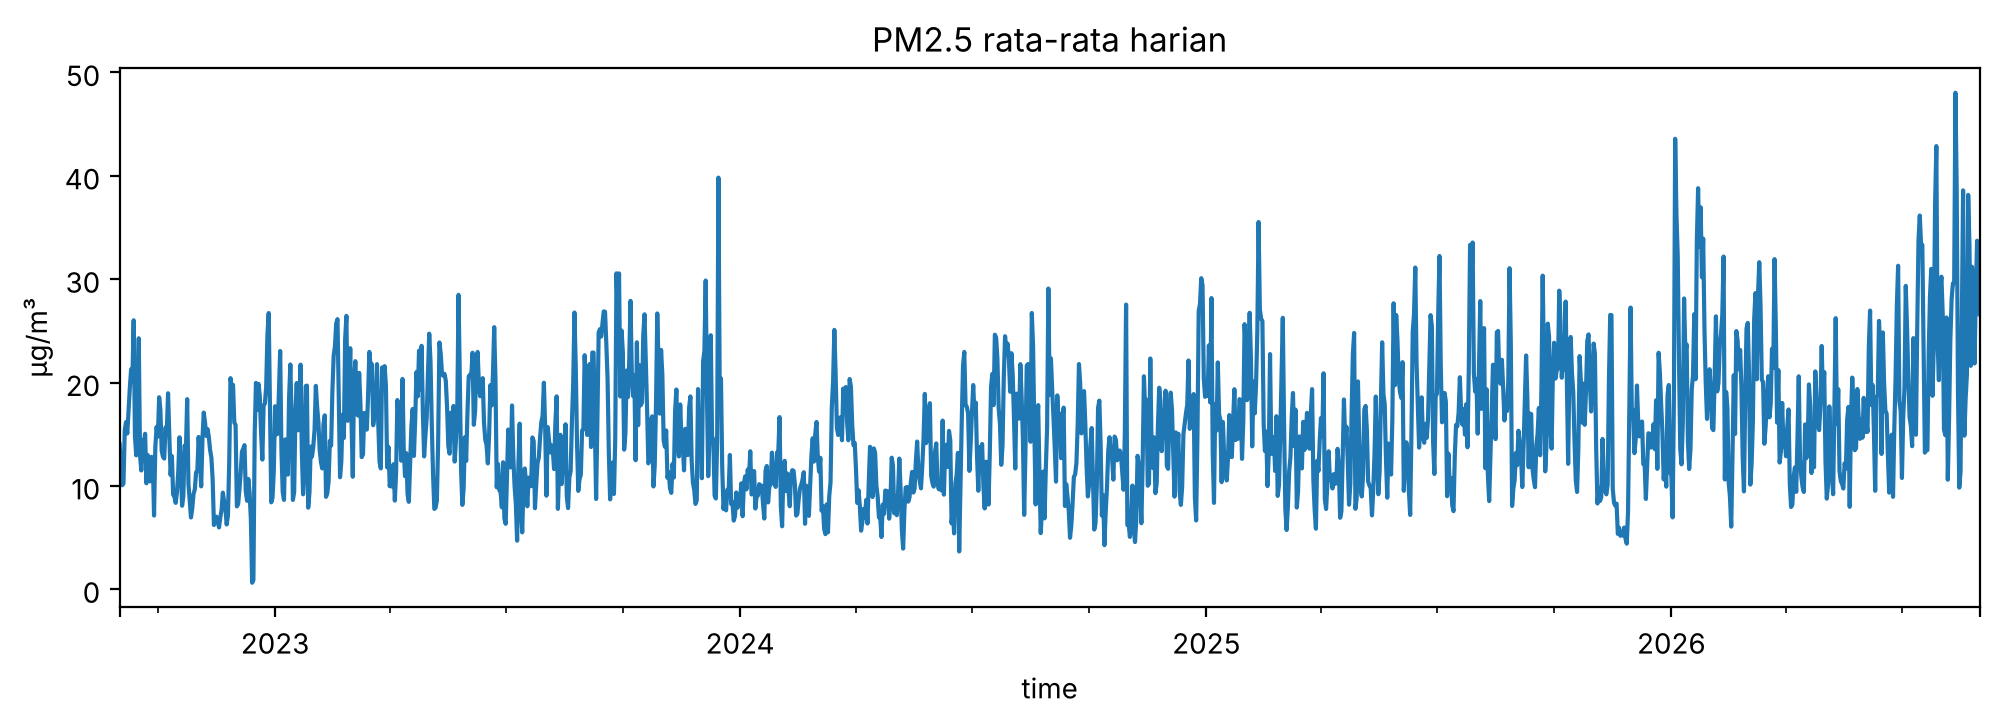

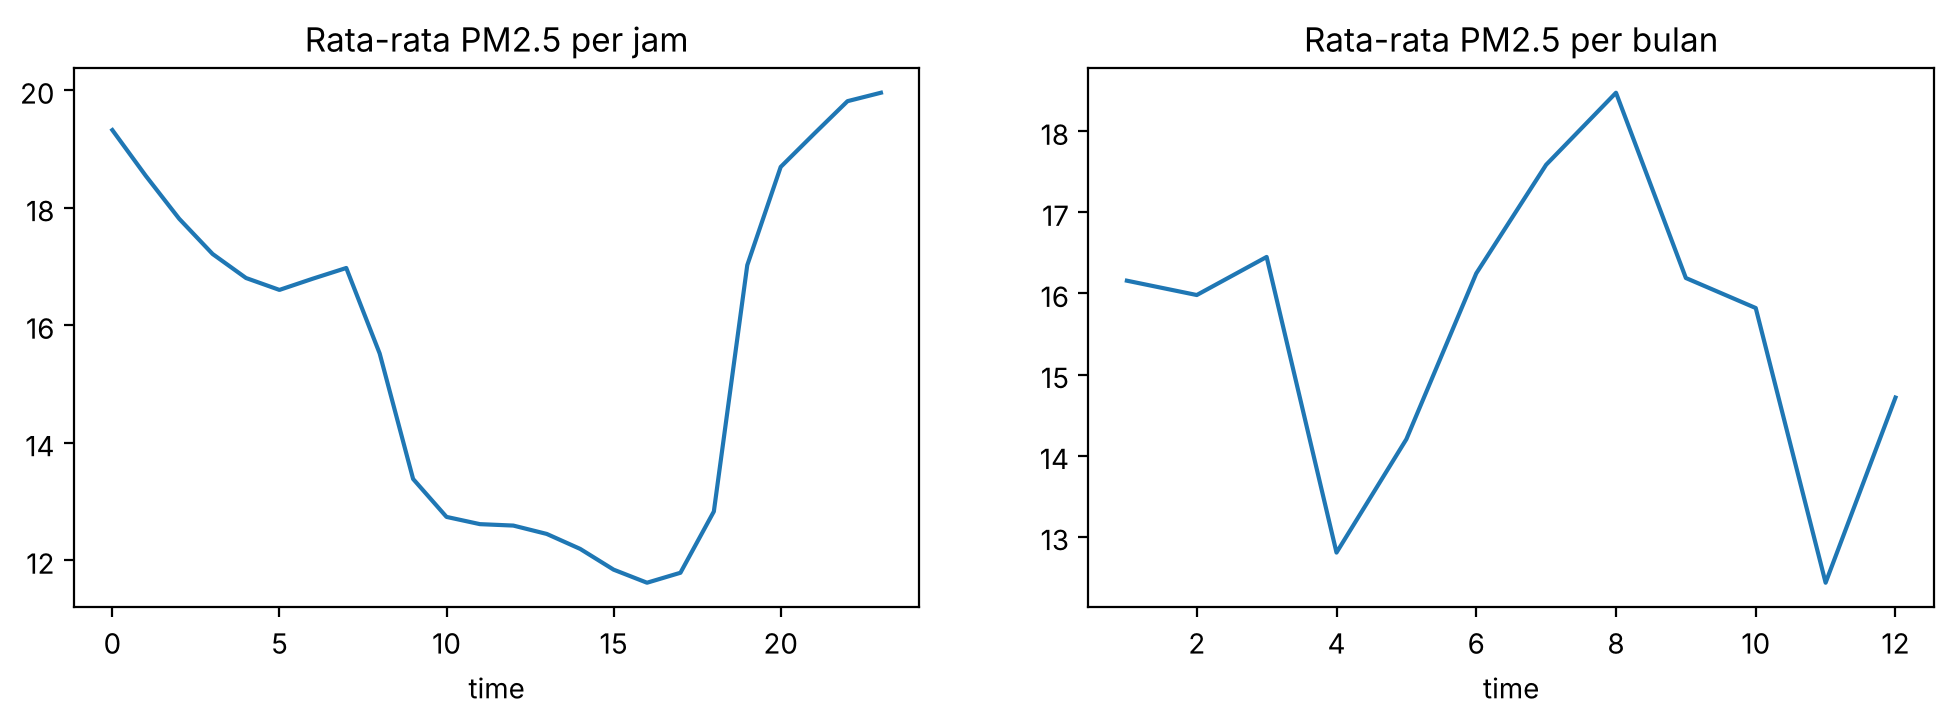

In [5]:
# Tren harian
df['pm2_5'].resample('D').mean().plot(title='PM2.5 rata-rata harian')
plt.ylabel('µg/m³'); plt.show()

# Pola per jam dan per bulan
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.groupby(df.index.hour)['pm2_5'].mean().plot(ax=ax[0], title='Rata-rata PM2.5 per jam')
df.groupby(df.index.month)['pm2_5'].mean().plot(ax=ax[1], title='Rata-rata PM2.5 per bulan')
plt.show()

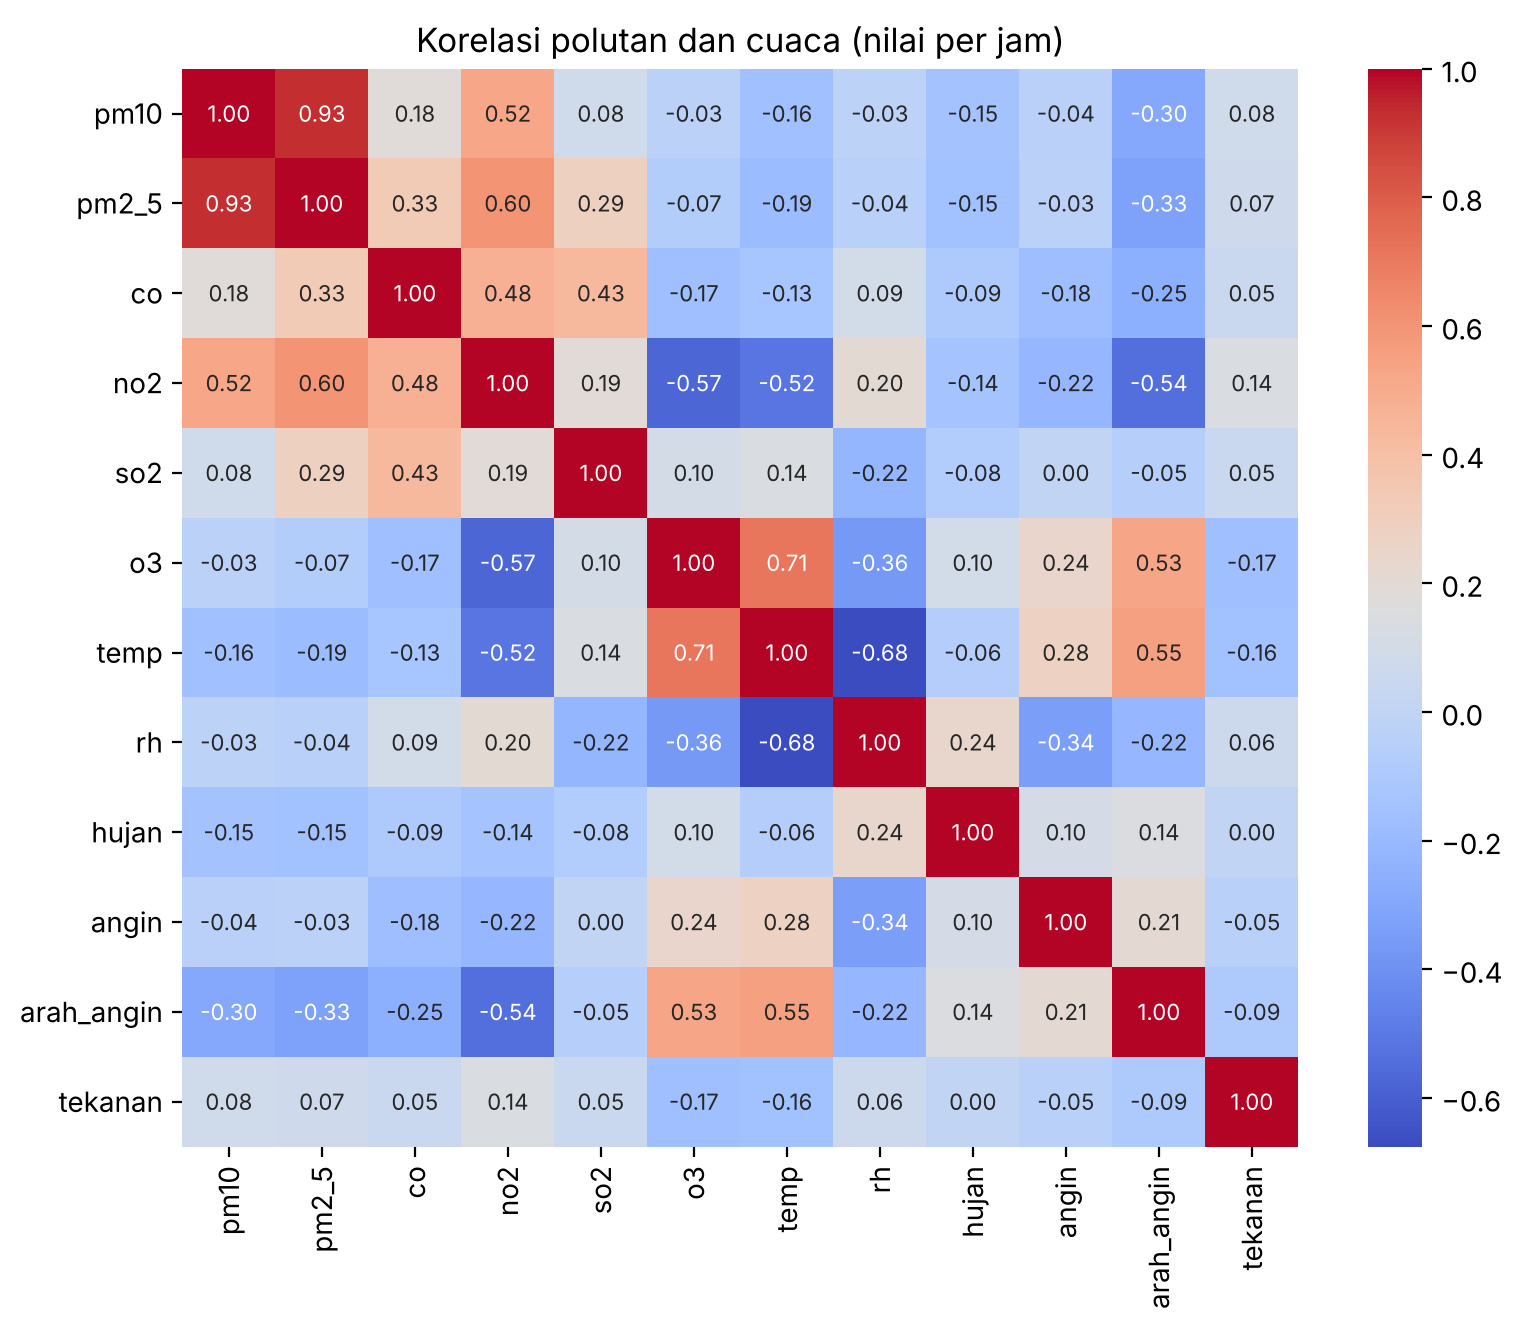

Korelasi PM2.5 dengan polutan lain:
pm10    0.93
co      0.33
no2     0.60
so2     0.29
o3     -0.07

Korelasi PM2.5 dengan variabel cuaca:
temp         -0.189
rh           -0.042
hujan        -0.155
angin        -0.030
arah_angin   -0.329
tekanan       0.071


In [6]:
# Korelasi polutan + cuaca
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 8})
plt.title('Korelasi polutan dan cuaca (nilai per jam)'); plt.show()

print('Korelasi PM2.5 dengan polutan lain:')
print(df[['pm10', 'co', 'no2', 'so2', 'o3']].corrwith(df['pm2_5']).round(2).to_string())
print('\nKorelasi PM2.5 dengan variabel cuaca:')
print(df[['temp', 'rh', 'hujan', 'angin', 'arah_angin', 'tekanan']].corrwith(df['pm2_5']).round(3).to_string())

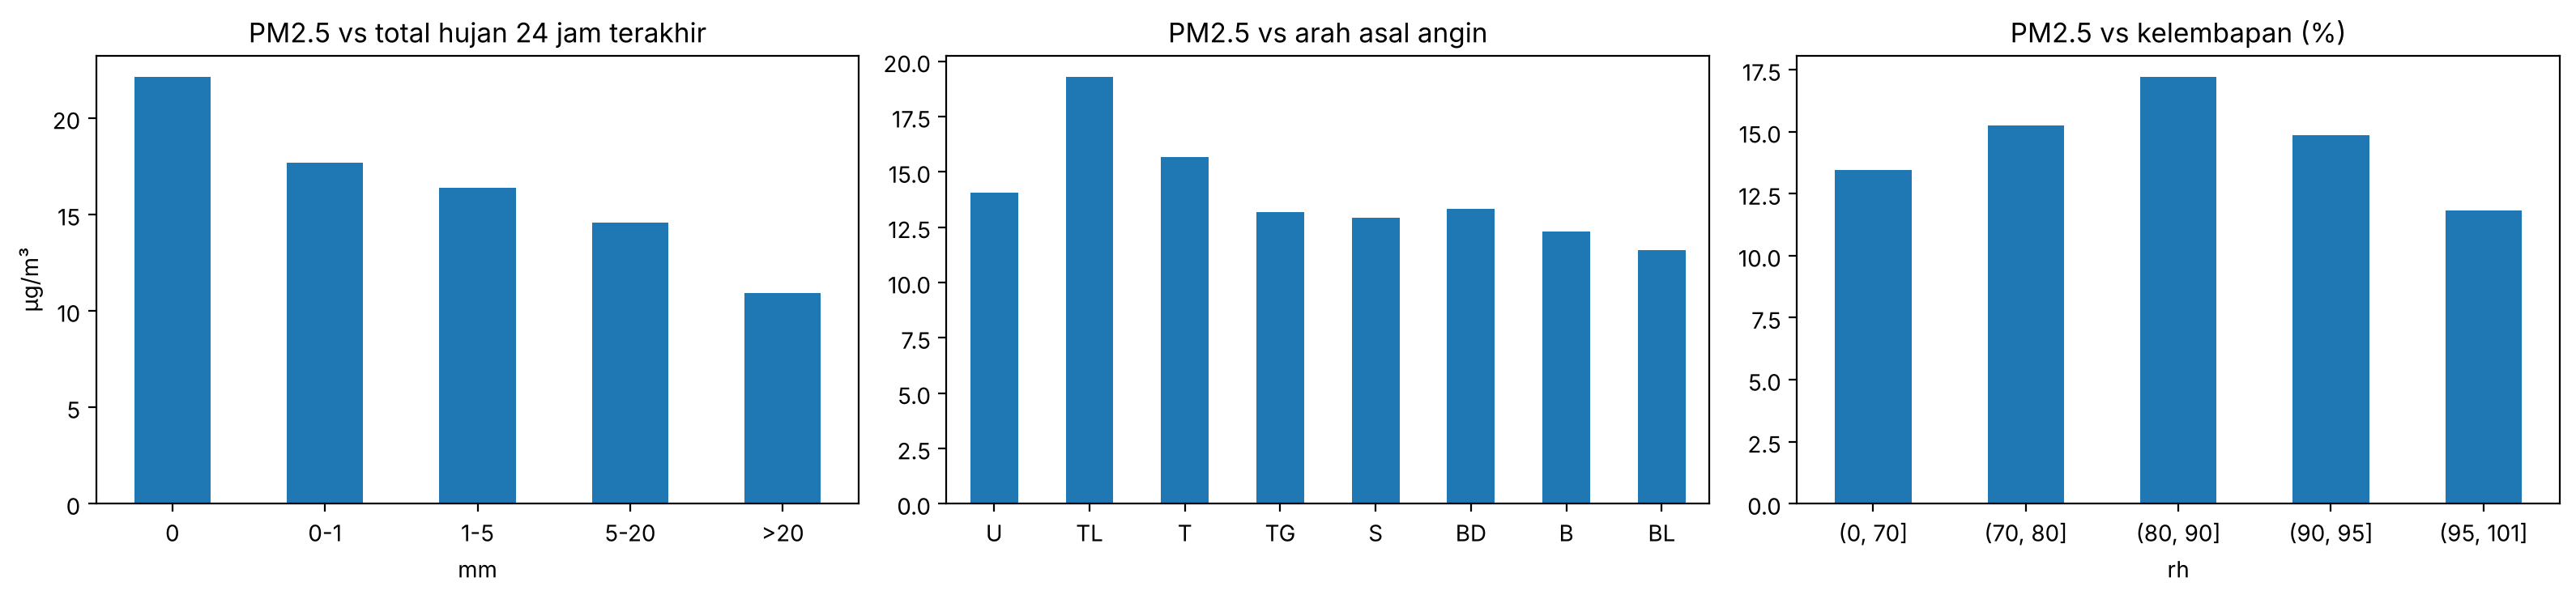

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

# (a) Hujan 24 jam terakhir vs PM2.5 (hujan membersihkan partikel)
h24 = df['hujan'].rolling(24).sum()
kelas = pd.cut(h24, [-0.01, 0.0, 1, 5, 20, 1e9], labels=['0', '0-1', '1-5', '5-20', '>20'])
df.groupby(kelas)['pm2_5'].mean().plot.bar(ax=ax[0], rot=0, title='PM2.5 vs total hujan 24 jam terakhir')
ax[0].set_xlabel('mm'); ax[0].set_ylabel('µg/m³')

# (b) Arah angin vs PM2.5 (8 sektor)
sektor = ((df['arah_angin'] + 22.5) // 45 % 8).astype(int)
nama = ['U', 'TL', 'T', 'TG', 'S', 'BD', 'B', 'BL']
g = df.groupby(sektor)['pm2_5'].mean(); g.index = [nama[i] for i in g.index]
g.plot.bar(ax=ax[1], rot=0, title='PM2.5 vs arah asal angin')

# (c) Kelembapan vs PM2.5
kelas_rh = pd.cut(df['rh'], [0, 70, 80, 90, 95, 101])
df.groupby(kelas_rh)['pm2_5'].mean().plot.bar(ax=ax[2], rot=0, title='PM2.5 vs kelembapan (%)')
plt.tight_layout(); plt.show()

## 3. Rekayasa Fitur
Prosedur dibuat sebagai fungsi di `fitur.py`, sehingga **identik** dipakai saat pelatihan dan saat prediksi di sistem (backend/dashboard).

- **Fitur polutan (89):** lag, rolling, tren, rasio, dan fitur waktu siklik.
- **Fitur cuaca (30):** suhu, kelembapan, tekanan, angin (nilai pada t, t-1, t-3, t-6, t-24 = 20 fitur); hujan (nilai t + total 6, 24, 72 jam = 4); arah angin (sin, cos, komponen u dan v = 4); tren tekanan (selisih 3 dan 24 jam = 2).

> **Aturan anti-kebocoran:** semua fitur hanya memakai informasi sampai jam **t**. Target adalah PM2.5 pada t+1, t+2, dan t+3 jam. Arah angin diubah ke sin/cos karena 359° dan 1° itu berdekatan; komponen u/v ikut karena arah angin tidak bermakna saat kecepatan angin nyaris nol.

In [8]:
%%writefile fitur.py
import numpy as np
import pandas as pd

HORIZONS = [1, 2, 3]   # horizon prediksi (jam ke depan)
LAGS = [1, 2, 3, 6, 12, 24, 48, 72, 168]
POLUTAN = ['pm10', 'pm2_5', 'co', 'no2', 'so2', 'o3']
CUACA = ['temp', 'rh', 'hujan', 'angin', 'arah_angin', 'tekanan']
CUACA_LAGS = [1, 3, 6, 24]
HUJAN_WINDOW = [6, 24, 72]
MIN_RIWAYAT = 200   # jam riwayat minimal untuk membentuk satu baris fitur


def fitur_polutan(d):
    """89 fitur dari data polutan (hanya memakai informasi sampai jam t)."""
    f = {}
    for c in POLUTAN:
        f[f'{c}_now'] = d[c]
        for l in LAGS:
            f[f'{c}_lag{l}'] = d[c].shift(l)

    pm = d['pm2_5']
    pm_s = pm.shift(1)
    for w in [6, 24, 72, 168]:
        f[f'pm2_5_rmean{w}'] = pm_s.rolling(w).mean()
        f[f'pm2_5_rstd{w}'] = pm_s.rolling(w).std()
    for w in [24, 72]:
        f[f'pm2_5_rmax{w}'] = pm_s.rolling(w).max()
        f[f'pm2_5_rmin{w}'] = pm_s.rolling(w).min()
    for c in ['pm10', 'co', 'no2', 'so2', 'o3']:
        f[f'{c}_rmean24'] = d[c].shift(1).rolling(24).mean()

    for k in [1, 3, 6, 24]:
        f[f'pm2_5_diff{k}'] = pm - pm.shift(k)
    f['pm2_5_ewm6'] = pm_s.ewm(span=6).mean()
    f['pm2_5_ewm24'] = pm_s.ewm(span=24).mean()
    f['pm_ratio'] = pm / (d['pm10'] + 1e-6)

    idx = d.index
    f['hour_sin'] = np.sin(2 * np.pi * idx.hour.values / 24)
    f['hour_cos'] = np.cos(2 * np.pi * idx.hour.values / 24)
    f['month_sin'] = np.sin(2 * np.pi * idx.month.values / 12)
    f['month_cos'] = np.cos(2 * np.pi * idx.month.values / 12)
    f['dayofweek'] = idx.dayofweek.values
    return pd.DataFrame(f, index=d.index)


def fitur_cuaca(d):
    """30 fitur dari data cuaca (hanya memakai informasi sampai jam t)."""
    f = {}
    for c in ['temp', 'rh', 'tekanan', 'angin']:
        f[f'{c}_now'] = d[c]
        for l in CUACA_LAGS:
            f[f'{c}_lag{l}'] = d[c].shift(l)

    # Hujan: akumulasi lebih informatif daripada nilai per jam
    h = d['hujan']
    f['hujan_now'] = h
    for w in HUJAN_WINDOW:
        f[f'hujan_sum{w}'] = h.rolling(w).sum()

    # Arah angin: sin/cos (siklik) dan komponen u, v (dikali kecepatan)
    rad = np.deg2rad(d['arah_angin'])
    f['arah_sin'] = np.sin(rad)
    f['arah_cos'] = np.cos(rad)
    f['wind_u'] = -d['angin'] * np.sin(rad)
    f['wind_v'] = -d['angin'] * np.cos(rad)

    # Tren tekanan
    f['tekanan_diff3'] = d['tekanan'] - d['tekanan'].shift(3)
    f['tekanan_diff24'] = d['tekanan'] - d['tekanan'].shift(24)
    return pd.DataFrame(f, index=d.index)


def buat_fitur(d, cuaca=True):
    """Tabel fitur lengkap. cuaca=False menghasilkan 89 fitur polutan saja."""
    f = fitur_polutan(d)
    if cuaca:
        f = pd.concat([f, fitur_cuaca(d)], axis=1)
    return f


class Kalibrator:
    """Kalibrasi probabilitas (isotonic). Disimpan di fitur.py agar joblib
    menemukan kelas ini saat model dimuat oleh dashboard/backend."""
    def fit(self, p, y):
        from sklearn.isotonic import IsotonicRegression
        self.m = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip').fit(
            np.asarray(p, dtype=float), np.asarray(y))
        return self

    def predict(self, p):
        return self.m.predict(np.asarray(p, dtype=float))

Overwriting fitur.py


In [9]:
sys.modules.pop('fitur', None)   # muat ulang fitur.py kalau baru diubah
from fitur import (buat_fitur, fitur_polutan, fitur_cuaca, Kalibrator,
                   HORIZONS, POLUTAN, CUACA, MIN_RIWAYAT)

feat = buat_fitur(df, cuaca=True)
targets = pd.DataFrame({f'y_{h}h': df['pm2_5'].shift(-h) for h in HORIZONS})

data = pd.concat([feat, targets], axis=1).dropna()
COLS_POLUTAN = list(fitur_polutan(df).columns)
COLS_CUACA = list(fitur_cuaca(df).columns)
POOL = COLS_POLUTAN + COLS_CUACA                  # seluruh kandidat fitur
assert set(POOL) == set(c for c in data.columns if not c.startswith('y_'))

print('Dataset akhir :', data.shape)
print(f'Fitur polutan   : {len(COLS_POLUTAN)}')
print(f'Fitur cuaca     : {len(COLS_CUACA)}')
print(f'Kandidat fitur  : {len(POOL)}')
print(f'Baris hilang karena riwayat/target: {len(df) - len(data)}')

Dataset akhir : (34893, 122)
Fitur polutan   : 89
Fitur cuaca     : 30
Kandidat fitur  : 119
Baris hilang karena riwayat/target: 171


## 4. Pembagian Data & Validasi Silang Deret Waktu
- **Data test (15% terakhir)** dipisahkan lebih dulu dan **tidak dipakai untuk tuning**.
- **Data development (85% awal)** dipakai untuk pemilihan fitur dengan **TimeSeriesSplit (walk-forward, 5 fold)**: train selalu di masa lalu, validasi di masa setelahnya.
- `gap` = horizon terjauh (3 jam) dibuang di antara train dan validasi, karena target berupa nilai t+h, sehingga tidak ada tumpang tindih informasi.
- K-Fold biasa (acak) **tidak dipakai** karena merusak autokorelasi dan membocorkan informasi masa depan.

In [10]:
n = len(data)
dev  = data.iloc[:int(n * 0.85)]     # untuk CV + pelatihan
test = data.iloc[int(n * 0.85):]     # murni sampai evaluasi akhir

GAP = max(HORIZONS)
folds = list(TimeSeriesSplit(n_splits=5, gap=GAP).split(dev))

print(f'Dev : {dev.index.min()} -> {dev.index.max()} ({len(dev)} baris)')
print(f'Test: {test.index.min()} -> {test.index.max()} ({len(test)} baris)\n')
for i, (a, b) in enumerate(folds, 1):
    print(f'Fold {i}: train {dev.index[a[0]].date()} -> {dev.index[a[-1]].date()} ({len(a):>5}) | '
          f'val {dev.index[b[0]].date()} -> {dev.index[b[-1]].date()} ({len(b)})')

Dev : 2022-09-08 00:00:00 -> 2026-01-25 18:00:00 (29659 baris)
Test: 2026-01-25 19:00:00 -> 2026-08-31 20:00:00 (5234 baris)

Fold 1: train 2022-09-08 -> 2023-04-01 ( 4941) | val 2023-04-02 -> 2023-10-24 (4943)
Fold 2: train 2022-09-08 -> 2023-10-24 ( 9884) | val 2023-10-24 -> 2024-05-17 (4943)
Fold 3: train 2022-09-08 -> 2024-05-17 (14827) | val 2024-05-17 -> 2024-12-09 (4943)
Fold 4: train 2022-09-08 -> 2024-12-09 (19770) | val 2024-12-09 -> 2025-07-03 (4943)
Fold 5: train 2022-09-08 -> 2025-07-03 (24713) | val 2025-07-03 -> 2026-01-25 (4943)


## 5. Baseline & Seleksi Fitur
**Baseline** sebagai pembanding: *Persistence* (PM2.5 t+h = PM2.5 sekarang) dan *Ridge* (model linear).

**Seleksi fitur:** 119 kandidat terlalu banyak untuk satu horizon, sehingga dipilih **K fitur teratas** per horizon. Ranking fitur dihitung **di dalam tiap fold** (hanya dari data train fold, tanpa melihat validasi). Jumlah K (15, 30, 45, atau semua) dipilih dari rata-rata RMSE antar-fold. Dipilih K **terkecil** yang RMSE-nya dalam 1% dari terbaik (parsimoni: model lebih sederhana dengan akurasi setara).

In [11]:
results = []
def rmse_f(a, b): return np.sqrt(mean_squared_error(a, b))

def evaluate(y_true, y_pred, model, h):
    results.append({'Horizon': h, 'Model': model,
                    'RMSE': rmse_f(y_true, y_pred),
                    'MAE': mean_absolute_error(y_true, y_pred),
                    'R2': r2_score(y_true, y_pred)})

# Baseline: Persistence dan Ridge
for h in HORIZONS:
    y = f'y_{h}h'
    evaluate(test[y], test['pm2_5_now'], 'Persistence', h)
    r = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(dev[POOL], dev[y])
    evaluate(test[y], r.predict(test[POOL]), 'Ridge', h)
print('Baseline selesai untuk', len(HORIZONS), 'horizon')

Baseline selesai untuk 3 horizon


In [12]:
# Parameter untuk CV (tanpa early stopping agar perbandingan antar-K adil)
XGB_CV = dict(n_estimators=400, learning_rate=0.05, max_depth=3, min_child_weight=30,
              subsample=0.7, colsample_bytree=0.6, reg_lambda=30, reg_alpha=1.0, gamma=1.0,
              tree_method='hist', random_state=42, n_jobs=-1)
# Parameter model final (early stopping pada potongan terakhir data dev)
XGB_FINAL = {**XGB_CV, 'n_estimators': 3000, 'learning_rate': 0.03, 'early_stopping_rounds': 100}

K_CANDIDATES = [15, 30, 45, len(POOL)]      # len(POOL) = pakai semua fitur

# ---- Cross-validation walk-forward untuk memilih K ----
cv_rows = []
t0 = time.time()
for h in HORIZONS:
    y = f'y_{h}h'
    for fi, (a, b) in enumerate(folds, 1):
        tr, va = dev.iloc[a], dev.iloc[b]
        m_all = XGBRegressor(**XGB_CV).fit(tr[POOL], tr[y])             # ranking fitur + K = semua
        urut = pd.Series(m_all.feature_importances_, index=POOL).sort_values(ascending=False)
        for K in K_CANDIDATES:
            if K == len(POOL):
                pred = m_all.predict(va[POOL])
            else:
                cols = list(urut.index[:K])
                pred = XGBRegressor(**XGB_CV).fit(tr[cols], tr[y]).predict(va[cols])
            cv_rows.append({'Horizon': h, 'K': K, 'Fold': fi, 'RMSE': rmse_f(va[y], pred)})
    print(f't+{h}h selesai | {time.time() - t0:.0f} dtk')

cv_fold = pd.DataFrame(cv_rows)
cv_df = (cv_fold.groupby(['Horizon', 'K'])['RMSE'].agg(['mean', 'std'])
         .rename(columns={'mean': 'CV RMSE (mean)', 'std': 'CV RMSE (std)'}).reset_index())
print('\nRMSE CV rata-rata per horizon dan jumlah fitur K:')
display(cv_df.pivot(index='Horizon', columns='K', values='CV RMSE (mean)').round(3))

t+1h selesai | 17 dtk


t+2h selesai | 33 dtk


t+3h selesai | 51 dtk

RMSE CV rata-rata per horizon dan jumlah fitur K:


K,15,30,45,119
Horizon,,,,
1,2.146,2.096,2.080,2.116
2,3.181,3.113,3.058,3.106
3,3.926,3.808,3.804,3.802


In [13]:
def pilih_K(h):
    g = cv_df[cv_df.Horizon == h]
    best = g['CV RMSE (mean)'].min()
    return int(g[g['CV RMSE (mean)'] <= best * 1.01]['K'].min())

# ---- Latih model final tiap horizon ----
cut = int(len(dev) * 0.85)
fit_part, es_part = dev.iloc[:cut - GAP], dev.iloc[cut:]       # es_part = validasi early stopping

final_models = {}
for h in HORIZONS:
    y = f'y_{h}h'
    K = pilih_K(h)
    urut = pd.Series(XGBRegressor(**XGB_CV).fit(dev[POOL], dev[y]).feature_importances_,
                     index=POOL).sort_values(ascending=False)
    cols = list(urut.index[:K])
    m = XGBRegressor(**XGB_FINAL)
    m.fit(fit_part[cols], fit_part[y], eval_set=[(es_part[cols], es_part[y])], verbose=False)
    final_models[h] = {'XGBoost': m, 'features': cols, 'K': K}
    evaluate(test[y], m.predict(test[cols]), 'XGBoost (final)', h)
    print(f't+{h}h | K = {K:>3} fitur | pohon (early stopping) = {m.best_iteration + 1}')

KOLOM_INPUT = POLUTAN + CUACA       # kolom yang harus dikirim sistem ke fitur.py

t+1h | K =  30 fitur | pohon (early stopping) = 946


t+2h | K =  45 fitur | pohon (early stopping) = 1567


t+3h | K =  30 fitur | pohon (early stopping) = 1362


### 5.1 Cek overfitting model final
Membandingkan RMSE pada data train (dev), rata-rata CV, dan test. Gap kecil berarti model tidak menghafal data latih.

In [14]:
rows = []
for h in HORIZONS:
    y = f'y_{h}h'; cols = final_models[h]['features']; m = final_models[h]['XGBoost']
    tr_r = rmse_f(dev[y], m.predict(dev[cols])); te_r = rmse_f(test[y], m.predict(test[cols]))
    cvm = cv_df[(cv_df.Horizon == h) & (cv_df.K == final_models[h]['K'])]['CV RMSE (mean)'].iloc[0]
    rows.append({'Horizon': h, 'K': final_models[h]['K'], 'Dev (train)': tr_r, 'CV (mean)': cvm,
                 'Test': te_r, 'Gap (Test-Dev)': te_r - tr_r})
display(pd.DataFrame(rows).set_index('Horizon').round(3))

,K,Dev (train),CV (mean),Test,Gap (Test-Dev)
Horizon,,,,,
1,30,1.799,2.096,3.167,1.368
2,45,2.477,3.058,4.591,2.113
3,30,3.117,3.808,5.620,2.503


## 6. Evaluasi Akhir pada Data Test
Data test **tidak** dipakai untuk memilih fitur, K, maupun parameter; hanya untuk evaluasi akhir ini.

In [15]:
res_df = pd.DataFrame(results)

final = res_df[res_df.Model == 'XGBoost (final)'].set_index('Horizon')[['RMSE', 'MAE', 'R2']].round(3)
print('Metrik TEST model final:')
display(final)

print('Perbandingan seluruh model pada data test (RMSE):')
display(res_df.pivot(index='Horizon', columns='Model', values='RMSE').round(3))
print('Perbandingan seluruh model pada data test (R2):')
display(res_df.pivot(index='Horizon', columns='Model', values='R2').round(3))

Metrik TEST model final:


,RMSE,MAE,R2
Horizon,,,
1,3.167,1.788,0.913
2,4.591,2.887,0.817
3,5.620,3.720,0.726


Perbandingan seluruh model pada data test (RMSE):


Model,Persistence,Ridge,XGBoost (final)
Horizon,,,
1,3.616,3.022,3.167
2,5.812,4.566,4.591
3,7.466,5.529,5.620


Perbandingan seluruh model pada data test (R2):


Model,Persistence,Ridge,XGBoost (final)
Horizon,,,
1,0.887,0.921,0.913
2,0.707,0.819,0.817
3,0.516,0.734,0.726


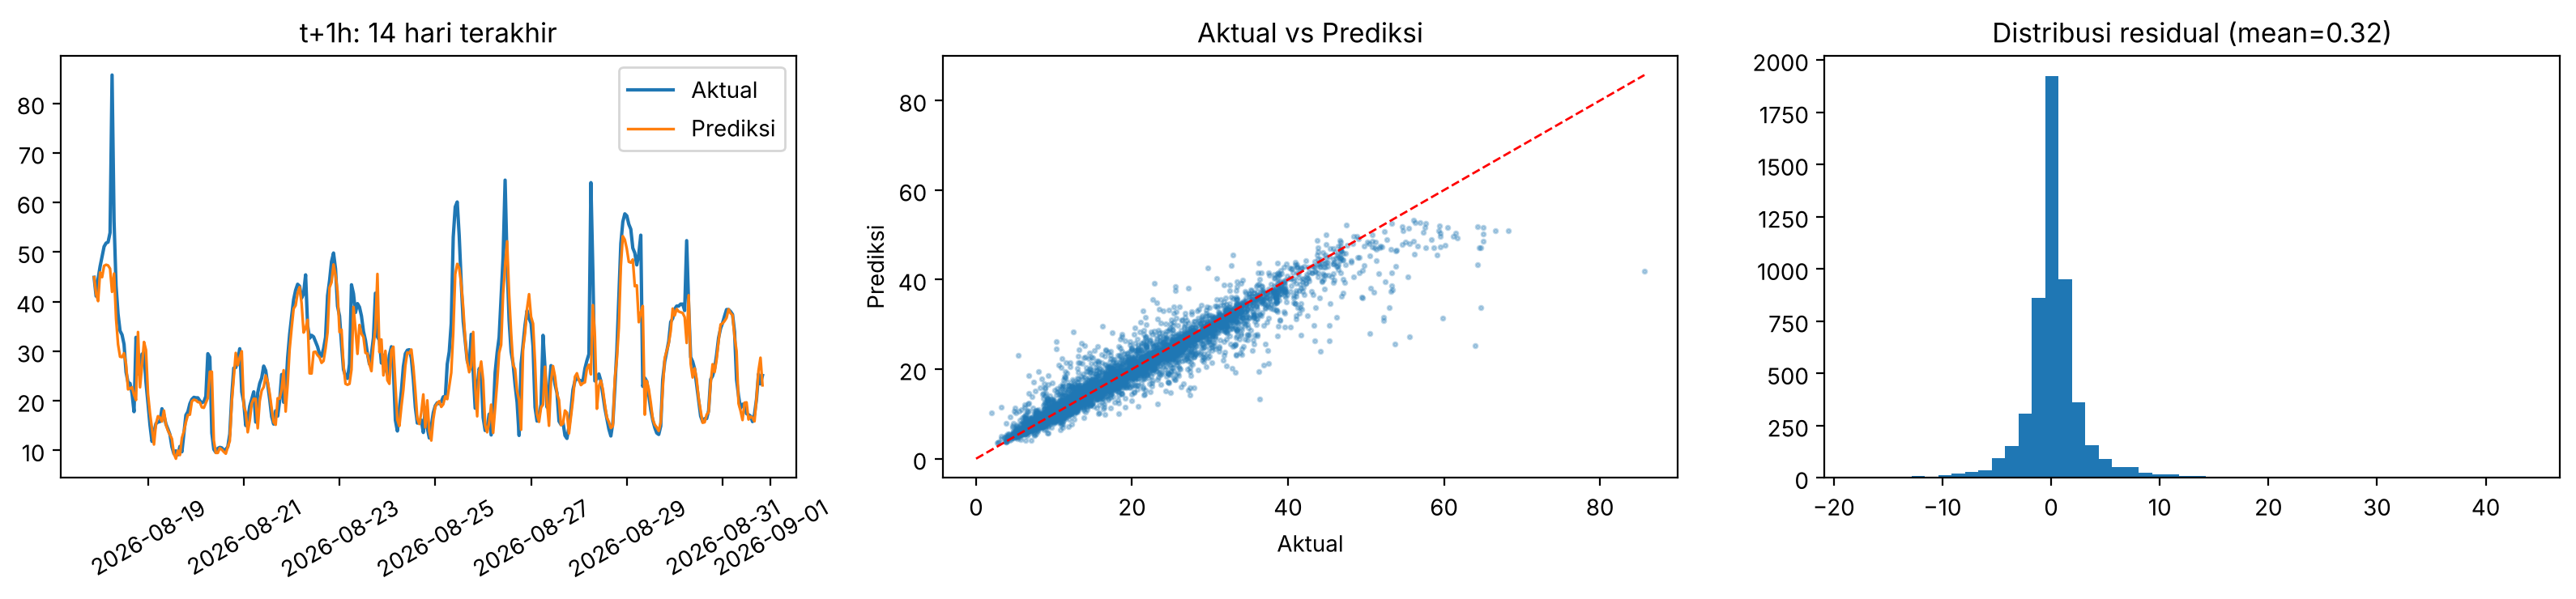

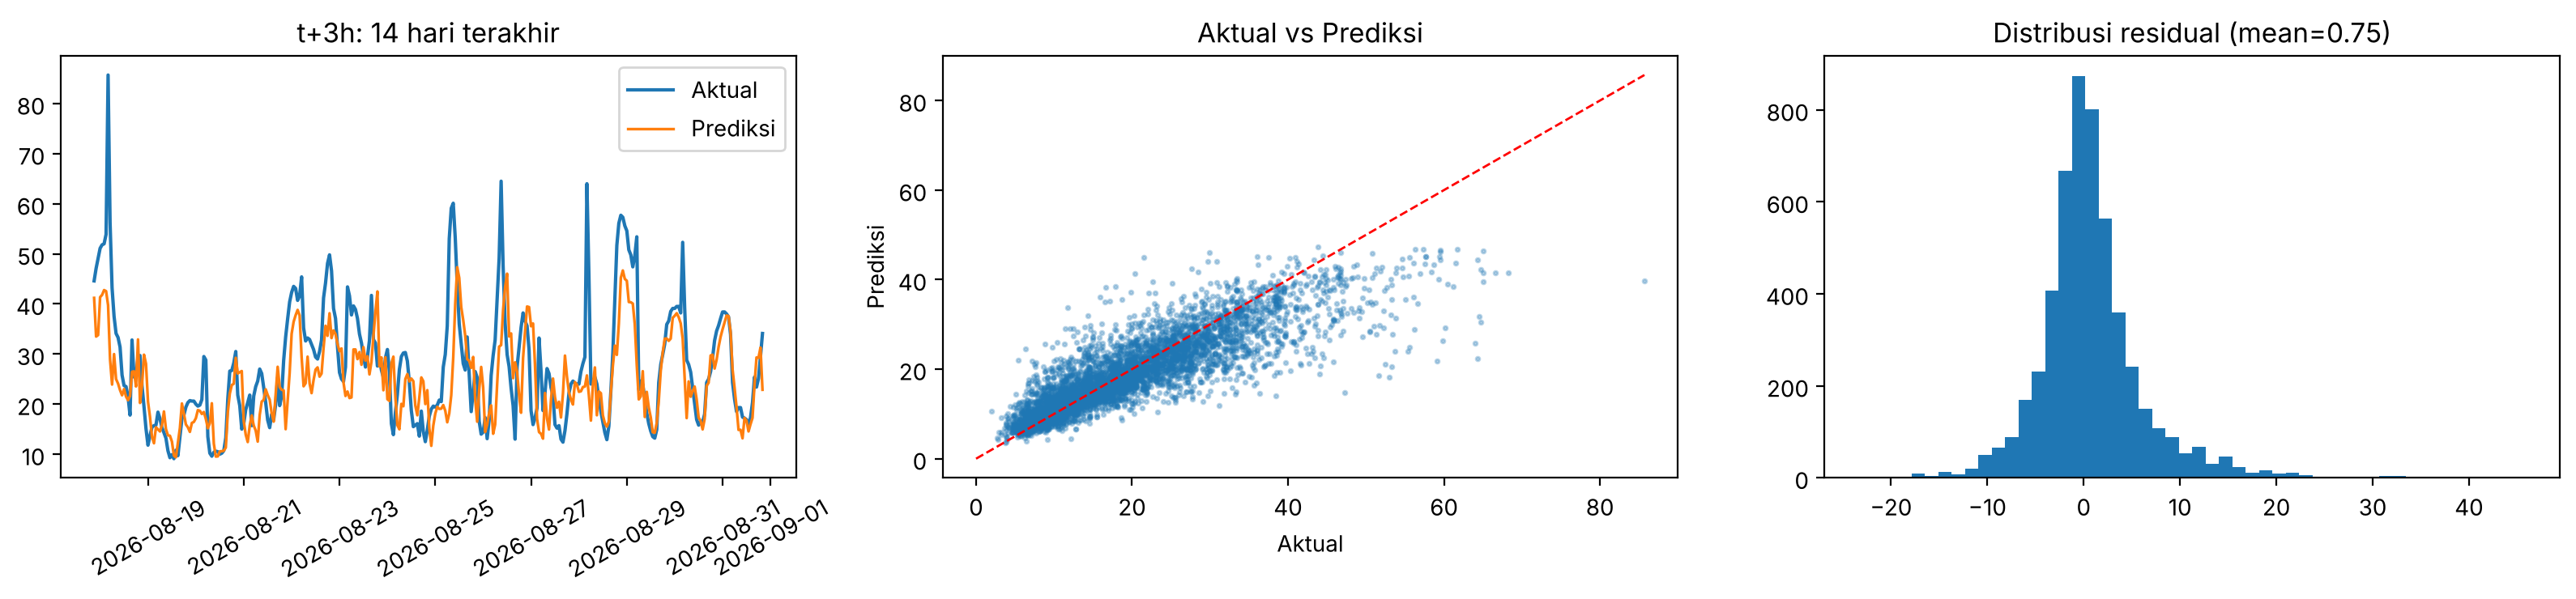

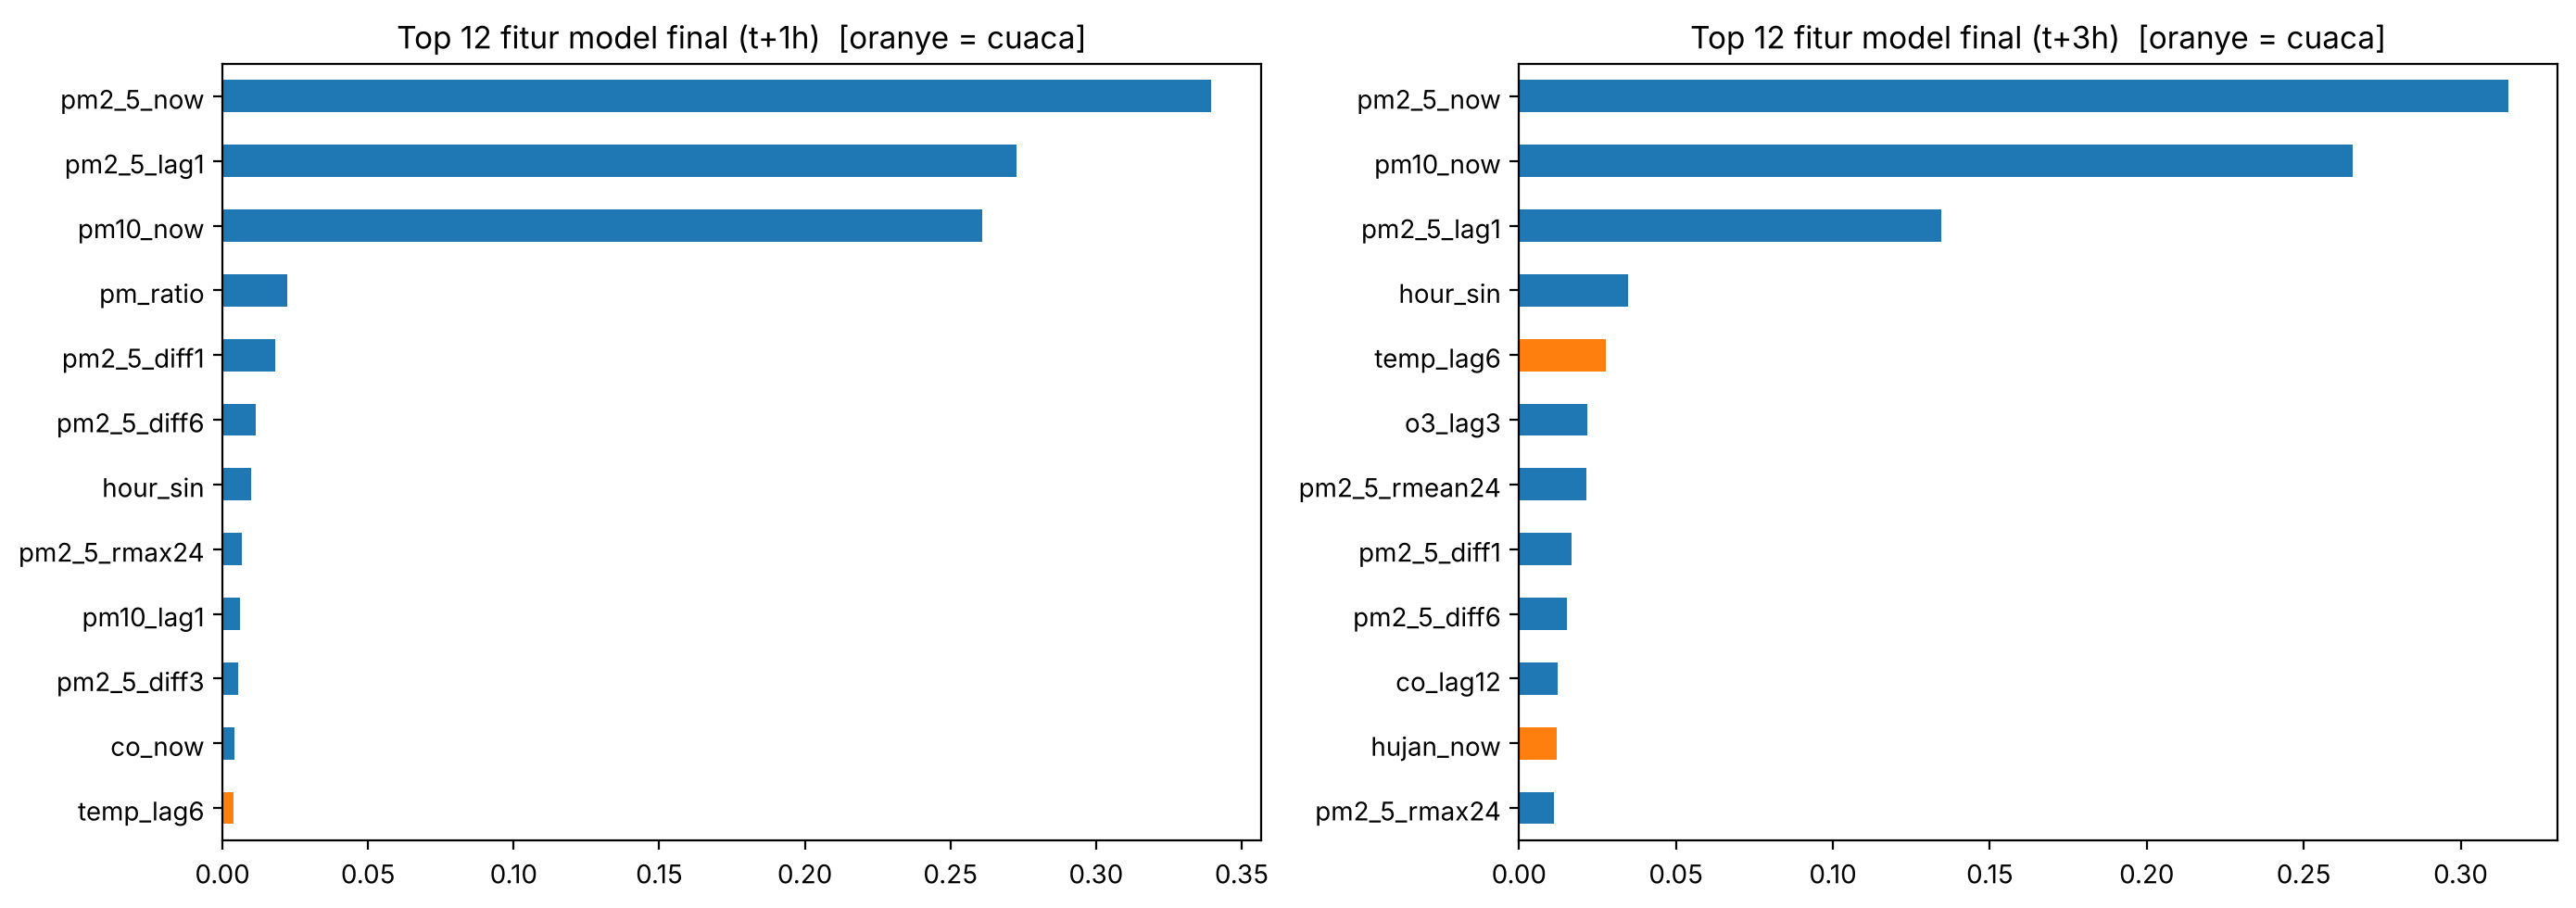

In [16]:
H_PLOT = [HORIZONS[0], HORIZONS[-1]]       # horizon terdekat dan terjauh untuk visualisasi

for h in H_PLOT:
    y = f'y_{h}h'; cols = final_models[h]['features']; mdl = final_models[h]['XGBoost']
    pred = mdl.predict(test[cols]); resid = test[y].values - pred

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    t = test.iloc[-24 * 14:]
    ax[0].plot(t.index, t[y], label='Aktual', lw=1.5)
    ax[0].plot(t.index, mdl.predict(t[cols]), label='Prediksi', lw=1.2)
    ax[0].set_title(f't+{h}h: 14 hari terakhir'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=30)
    ax[1].scatter(test[y], pred, s=3, alpha=0.3)
    lim = [0, max(test[y].max(), pred.max())]
    ax[1].plot(lim, lim, 'r--', lw=1)
    ax[1].set_xlabel('Aktual'); ax[1].set_ylabel('Prediksi'); ax[1].set_title('Aktual vs Prediksi')
    ax[2].hist(resid, bins=50); ax[2].set_title(f'Distribusi residual (mean={resid.mean():.2f})')
    plt.tight_layout(); plt.show()

# Feature importance model final (fitur cuaca diberi warna oranye)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, h in zip(axes, H_PLOT):
    imp = pd.Series(final_models[h]['XGBoost'].feature_importances_, index=final_models[h]['features']).nlargest(12).sort_values()
    imp.plot.barh(ax=ax, color=['tab:orange' if c in COLS_CUACA else 'tab:blue' for c in imp.index],
                  title=f'Top 12 fitur model final (t+{h}h)  [oranye = cuaca]')
plt.tight_layout(); plt.show()

## 7. Peringatan Dini (Alarm Waspada)
Regresi PM2.5 cenderung "menarik" prediksi ke tengah sehingga lonjakan ekstrem terlewat. Karena itu ditambahkan **klasifikasi alarm**: apakah PM2.5 pada t+h akan melewati ambang **Waspada = 35 µg/m³** (ambang 55,4 terlalu langka di data untuk dipelajari dengan andal).

1. Klasifier memakai **fitur terpilih dari tahap 5** (per horizon).
2. **Kalibrasi probabilitas** (isotonic) agar "peluang 40%" benar-benar berarti sekitar 40% kejadian.
3. **Ambang alarm dipilih dari prediksi out-of-fold** (F1 maksimum) pada fold terakhir data dev, lalu dilaporkan recall, precision, dan jumlah alarm di data test.

In [17]:
THR_WASPADA = 35.0
FOLD_AMBANG = 2      # kalibrasi/ambang memakai N fold terakhir (mirip kondisi data terbaru)

def kategori_pm25(v):
    if v <= 15.5:  return 'Baik'
    if v <= 55.4:  return 'Sedang'
    if v <= 150.4: return 'Tidak Sehat'
    if v <= 250.4: return 'Sangat Tidak Sehat'
    return 'Berbahaya'

REKOMENDASI = {
    'Baik': 'Kualitas udara baik. Aktivitas luar ruangan aman dilakukan.',
    'Sedang': 'Kelompok sensitif (asma, lansia, anak-anak) sebaiknya mengurangi aktivitas berat di luar ruangan.',
    'Tidak Sehat': 'Batasi aktivitas luar ruangan dan gunakan masker N95. Kelompok sensitif sebaiknya tetap di dalam ruangan.',
    'Sangat Tidak Sehat': 'Hindari aktivitas luar ruangan, gunakan masker N95, dan nyalakan penyaring udara jika ada.',
    'Berbahaya': 'Tetap di dalam ruangan dengan jendela tertutup. Cari bantuan medis jika mengalami sesak napas.',
}
REK_WASPADA = ('PERINGATAN DINI: potensi PM2.5 > 35 µg/m³. Kelompok sensitif sebaiknya mengurangi '
               'aktivitas luar ruangan dan menyiapkan masker N95.')

def peringatan_dini(nilai, horizon, alarm=False, prob=None):
    k = kategori_pm25(nilai)
    teks = f'Prediksi PM2.5 {horizon} jam ke depan: {nilai:.1f} µg/m³ ({k}). {REKOMENDASI[k]}'
    if alarm:
        teks += f' [{REK_WASPADA}' + (f' Peluang: {prob:.0%}]' if prob is not None else ']')
    return teks

def buat_clf(y_tr):
    spw = min((y_tr == 0).sum() / max(y_tr.sum(), 1), 20)      # penyeimbang kelas langka
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
                         subsample=0.8, colsample_bytree=0.6, reg_lambda=10,
                         scale_pos_weight=spw, tree_method='hist', random_state=42, n_jobs=-1)

def pilih_ambang(y_true, skor):
    """Ambang probabilitas dengan F1 tertinggi."""
    p, r, t = precision_recall_curve(y_true, skor)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
    return float(t[np.nanargmax(f1)])

# Prevalensi kejadian per fold (seberapa banyak kejadian untuk memilih ambang)
h_awal, h_akhir = HORIZONS[0], HORIZONS[-1]
display(pd.DataFrame([{'Fold': i, 'Baris val': len(b),
                       f'Kejadian t+{h_awal}': int((dev[f'y_{h_awal}h'].iloc[b] > THR_WASPADA).sum()),
                       f'Kejadian t+{h_akhir}': int((dev[f'y_{h_akhir}h'].iloc[b] > THR_WASPADA).sum())}
                      for i, (a, b) in enumerate(folds, 1)]).set_index('Fold'))

,Baris val,Kejadian t+1,Kejadian t+3
Fold,,,
1,4943,37,37
2,4943,26,26
3,4943,26,26
4,4943,219,221
5,4943,366,366


In [18]:
fold_pakai = folds[-FOLD_AMBANG:]
cls_models, cls_cal, cls_thr, rows = {}, {}, {}, []

for h in HORIZONS:
    y = f'y_{h}h'; cols = final_models[h]['features']
    yc_dev  = (dev[y]  > THR_WASPADA).astype(int)
    yc_test = (test[y] > THR_WASPADA).astype(int)

    # prediksi out-of-fold pada fold yang dipakai
    oof = pd.Series(np.nan, index=dev.index)
    for a, b in fold_pakai:
        tr, va = dev.iloc[a], dev.iloc[b]
        ytr_c = (tr[y] > THR_WASPADA).astype(int)
        oof.iloc[b] = buat_clf(ytr_c).fit(tr[cols], ytr_c).predict_proba(va[cols])[:, 1]
    ok = oof.notna()

    # kalibrasi + ambang dari out-of-fold
    cal = Kalibrator().fit(oof[ok].values, yc_dev[ok].values)
    thr = pilih_ambang(yc_dev[ok], cal.predict(oof[ok].values))

    # model final (dev) dievaluasi di test
    clf = buat_clf(yc_dev).fit(dev[cols], yc_dev)
    cls_models[h], cls_cal[h], cls_thr[h] = clf, cal, float(thr)

    p_raw = clf.predict_proba(test[cols])[:, 1]; p_cal = cal.predict(p_raw)
    alarm = p_cal >= thr
    rows.append({'Horizon': h, 'Kejadian test': int(yc_test.sum()),
                 'PR-AUC': round(average_precision_score(yc_test, p_cal), 3),
                 'Brier mentah': round(brier_score_loss(yc_test, p_raw), 4),
                 'Brier kalibrasi': round(brier_score_loss(yc_test, p_cal), 4),
                 'Ambang': round(thr, 3),
                 'Recall': round(recall_score(yc_test, alarm), 2),
                 'Precision': round(precision_score(yc_test, alarm, zero_division=0), 2),
                 'Jumlah alarm': int(alarm.sum())})

print(f'Prevalensi kejadian > {THR_WASPADA}: dev={(dev[f"y_{h_akhir}h"] > THR_WASPADA).mean():.1%}, '
      f'test={(test[f"y_{h_akhir}h"] > THR_WASPADA).mean():.1%}')
alarm_df = pd.DataFrame(rows).set_index('Horizon')
display(alarm_df)

Prevalensi kejadian > 35.0: dev=2.4%, test=8.8%


,Kejadian test,PR-AUC,Brier mentah,Brier kalibrasi,Ambang,Recall,Precision,Jumlah alarm
Horizon,,,,,,,,
1,462,0.898,0.0309,0.0244,0.474,0.95,0.73,597
2,461,0.769,0.0557,0.0421,0.350,0.90,0.48,863
3,460,0.656,0.0825,0.0535,0.367,0.82,0.42,895


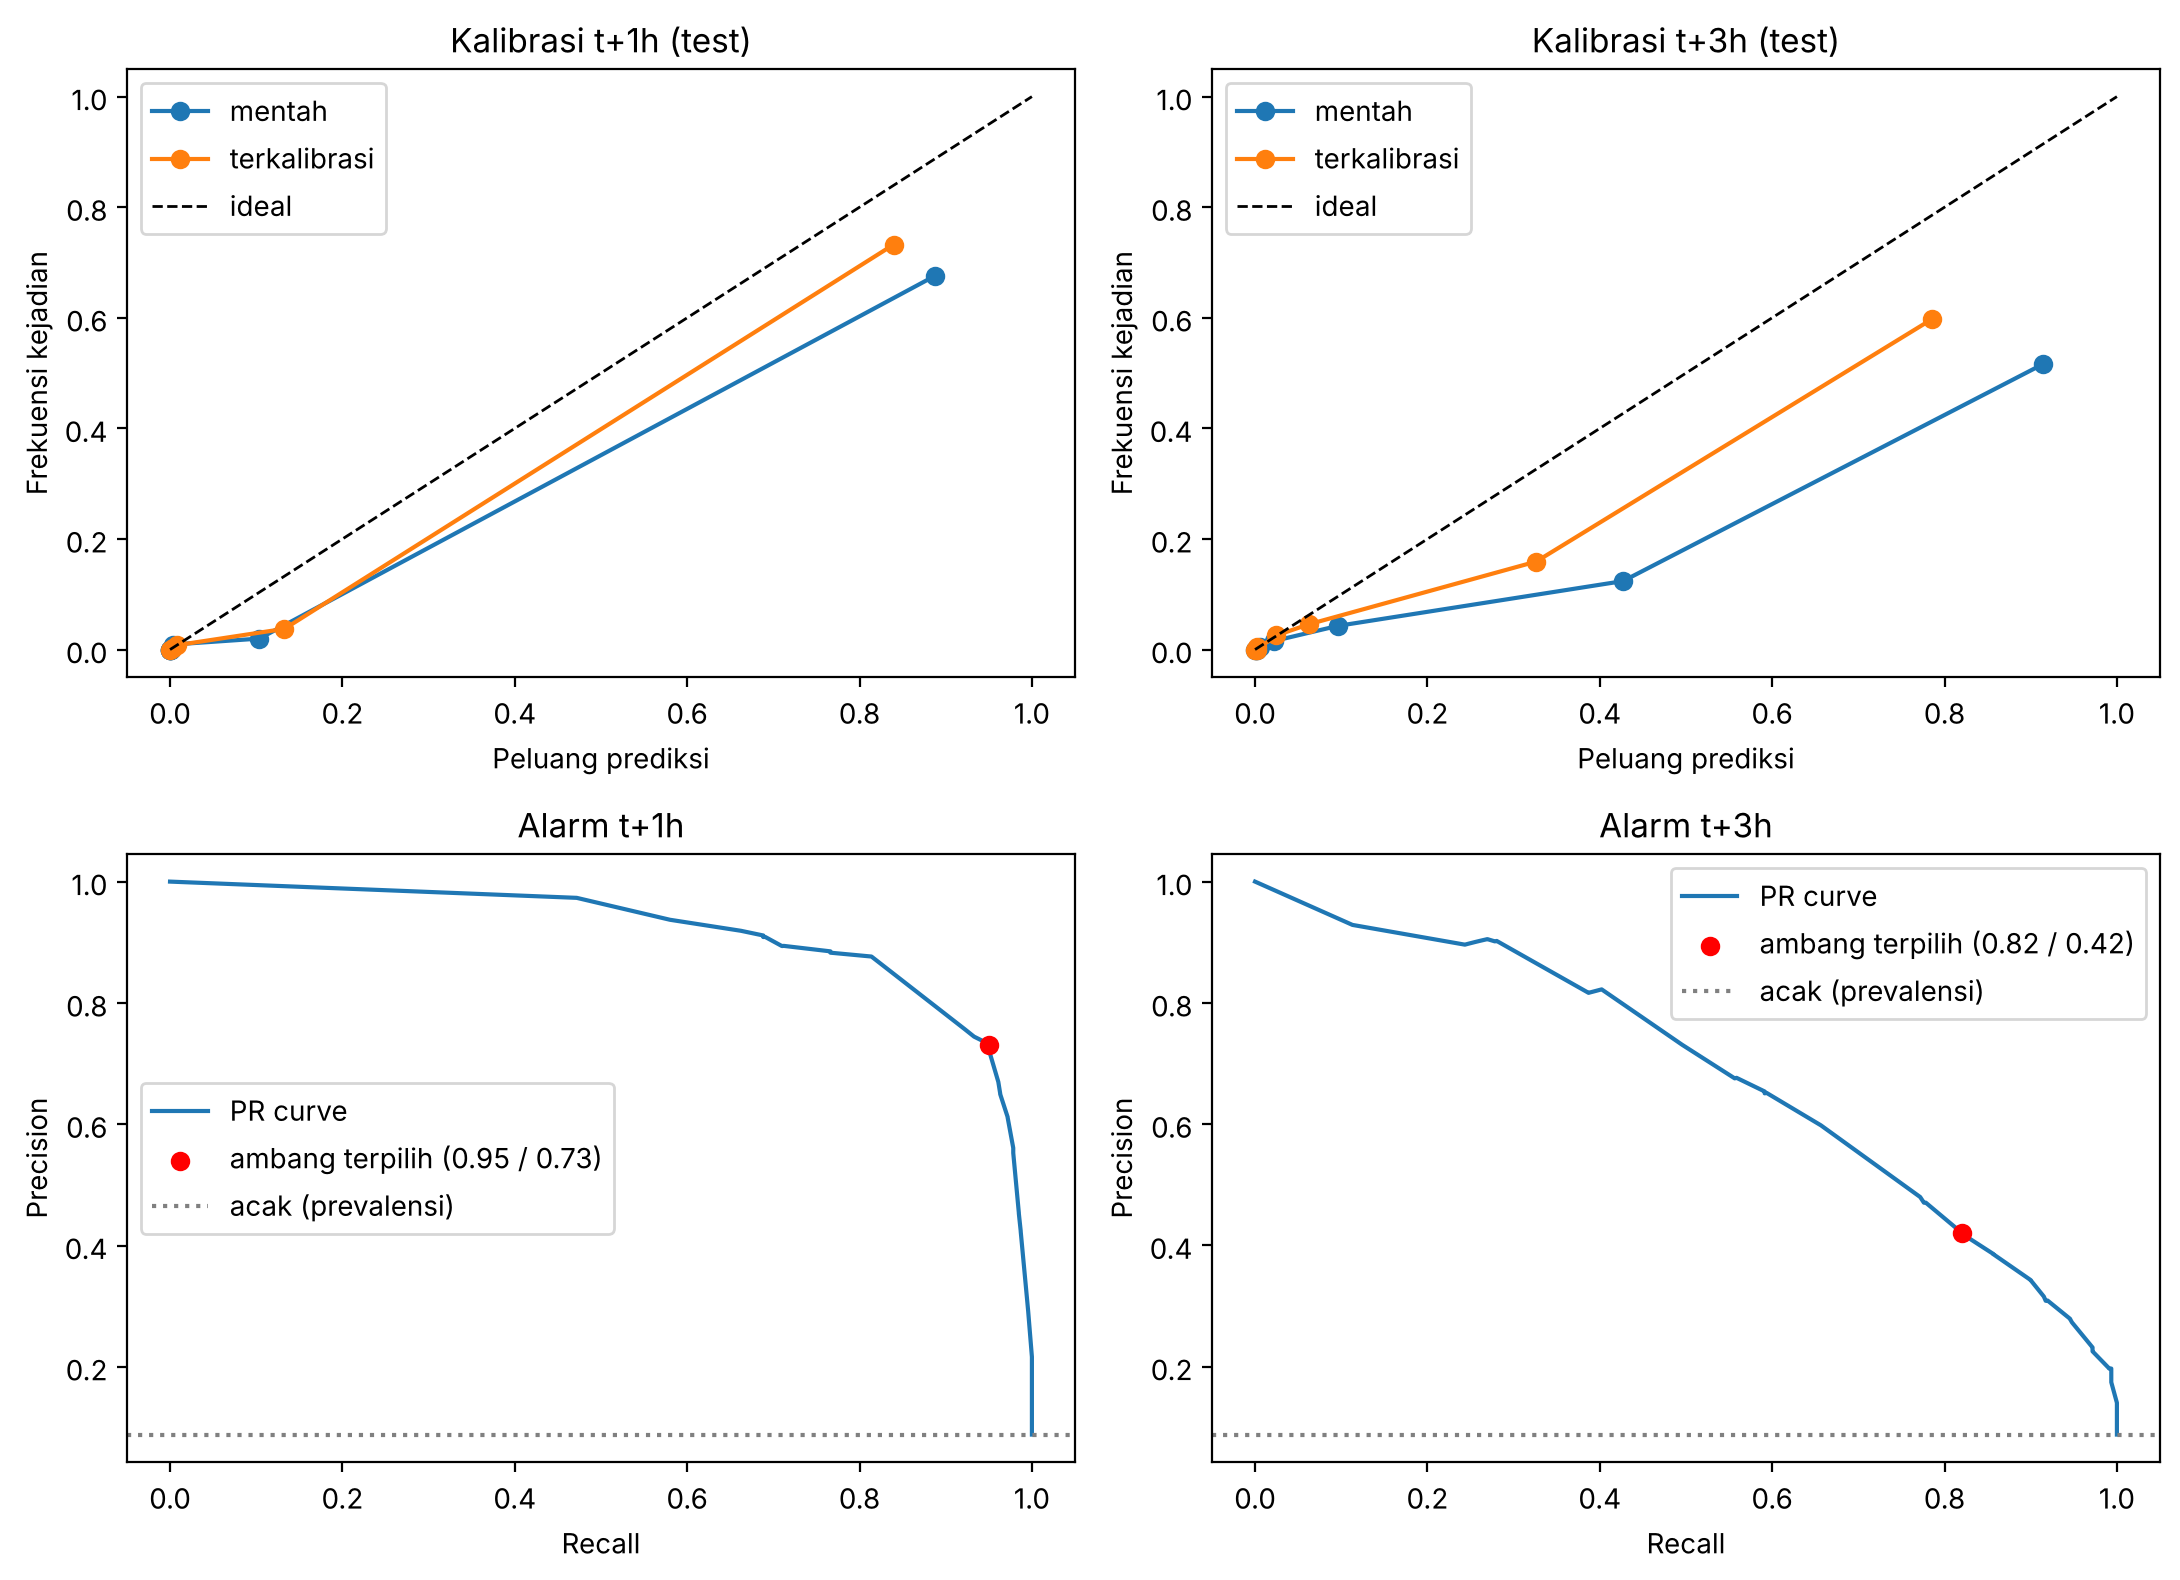

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for j, h in enumerate(H_PLOT):
    y = f'y_{h}h'; cols = final_models[h]['features']
    yc = (test[y] > THR_WASPADA).astype(int)
    p_raw = cls_models[h].predict_proba(test[cols])[:, 1]; p_cal = cls_cal[h].predict(p_raw)

    # kalibrasi: peluang prediksi vs frekuensi kejadian sebenarnya
    for p, lab in [(p_raw, 'mentah'), (p_cal, 'terkalibrasi')]:
        fy, fx = calibration_curve(yc, p, n_bins=8, strategy='quantile')
        ax[0, j].plot(fx, fy, 'o-', label=lab)
    ax[0, j].plot([0, 1], [0, 1], 'k--', lw=1, label='ideal')
    ax[0, j].set_title(f'Kalibrasi t+{h}h (test)'); ax[0, j].set_xlabel('Peluang prediksi')
    ax[0, j].set_ylabel('Frekuensi kejadian'); ax[0, j].legend()

    # trade-off recall vs precision pada ambang terpilih
    pr, rc, _ = precision_recall_curve(yc, p_cal)
    ax[1, j].plot(rc, pr, label='PR curve')
    r_, p_ = alarm_df.loc[h, 'Recall'], alarm_df.loc[h, 'Precision']
    ax[1, j].scatter([r_], [p_], c='r', zorder=3, label=f'ambang terpilih ({r_:.2f} / {p_:.2f})')
    ax[1, j].axhline(yc.mean(), color='gray', ls=':', label='acak (prevalensi)')
    ax[1, j].set_xlabel('Recall'); ax[1, j].set_ylabel('Precision'); ax[1, j].set_title(f'Alarm t+{h}h'); ax[1, j].legend()
plt.tight_layout(); plt.show()

## 8. Finalisasi Model & Penyimpanan
Setelah evaluasi di data test selesai (angka di atas **tidak diubah lagi**), model dilatih ulang pada **seluruh data (dev + test)** supaya sistem memakai pola paling baru.

- Jumlah pohon regresi = iterasi terbaik early stopping × 1,15 (data bertambah ± 18%).
- Fitur, K, kalibrator, dan ambang alarm **tidak diubah** (berasal dari data dev).
- Metrik yang disimpan di `meta` tetap metrik **test dari model sebelum dilatih ulang**.

File yang dihasilkan: `model_pm25.joblib` (regresi, klasifier alarm, kalibrator, ambang, daftar fitur). Bawa bersama `fitur.py` ke backend.

In [20]:
reg_save, cls_save = {}, {}
for h in HORIZONS:
    y = f'y_{h}h'; cols = final_models[h]['features']
    p = {k: v for k, v in XGB_FINAL.items() if k != 'early_stopping_rounds'}
    p['n_estimators'] = int((final_models[h]['XGBoost'].best_iteration + 1) * 1.15)
    reg_save[h] = XGBRegressor(**p).fit(data[cols], data[y])
    yc_all = (data[y] > THR_WASPADA).astype(int)
    cls_save[h] = buat_clf(yc_all).fit(data[cols], yc_all)
print('Model dilatih ulang pada seluruh data:', data.index.min(), '->', data.index.max())

Model dilatih ulang pada seluruh data: 2022-09-08 00:00:00 -> 2026-08-31 20:00:00


In [21]:
meta = {
    'versi_notebook': 'v7',
    'horizons': HORIZONS,
    'features_per_horizon': {h: final_models[h]['features'] for h in HORIZONS},
    'kolom_input': KOLOM_INPUT,                 # kolom yang harus ada pada riwayat input sistem
    'pakai_cuaca': True,                        # dipertahankan agar kompatibel dengan backend
    'thr_waspada': THR_WASPADA,
    'ambang_alarm_prob': cls_thr,               # berlaku untuk probabilitas TERKALIBRASI
    'kalibrasi': 'isotonic',
    'ambang_kategori': [15.5, 55.4, 150.4, 250.4],
    'min_riwayat': MIN_RIWAYAT,
    'periode_dev': (str(dev.index.min()), str(dev.index.max())),
    'periode_latih_final': (str(data.index.min()), str(data.index.max())),
    'metrik_test': res_df[res_df.Model == 'XGBoost (final)'].round(3).to_dict('records'),
    'alarm_test': alarm_df.reset_index().to_dict('records'),
}
joblib.dump({'reg_models': reg_save, 'cls_models': cls_save, 'cls_cal': cls_cal, 'meta': meta},
            'model_pm25.joblib', compress=3)
print('Tersimpan: model_pm25.joblib |', round(os.path.getsize('model_pm25.joblib') / 1e6, 1), 'MB')
print('File untuk backend: model_pm25.joblib dan fitur.py')

Tersimpan: model_pm25.joblib | 1.1 MB
File untuk backend: model_pm25.joblib dan fitur.py


## 9. Uji Integrasi Sistem
1. **Konsistensi pelatihan vs inferensi:** fitur yang dihitung dari potongan riwayat (seperti di backend) harus sama dengan fitur saat pelatihan.
2. **Prediksi end-to-end** dari file `.joblib`.

In [22]:
# 1) Fitur dari riwayat 300 jam harus sama dengan fitur penuh pada jam yang sama
for akhir in [len(df), len(df) - 500, len(df) - 5000]:
    pot = df.iloc[akhir - 300:akhir]
    selisih = (buat_fitur(pot).iloc[-1] - feat.iloc[akhir - 1]).abs().max()
    print(f'Jam {pot.index[-1]} | selisih fitur maksimum = {selisih:.2e}')
    assert selisih < 1e-3, 'Fitur inferensi berbeda dari fitur pelatihan!'
print('OK: fitur inferensi identik dengan fitur pelatihan.')

Jam 2026-08-31 23:00:00 | selisih fitur maksimum = 3.70e-11
Jam 2026-08-11 03:00:00 | selisih fitur maksimum = 4.93e-11
Jam 2026-02-04 15:00:00 | selisih fitur maksimum = 3.14e-10
OK: fitur inferensi identik dengan fitur pelatihan.


In [23]:
# 2) Muat dari file lalu prediksi dari riwayat, seperti yang dilakukan backend
sys.modules.pop('fitur', None)
from fitur import buat_fitur, Kalibrator                      # Kalibrator diperlukan joblib saat memuat model
paket = joblib.load('model_pm25.joblib')
RM, CM, CAL, meta_load = paket['reg_models'], paket['cls_models'], paket['cls_cal'], paket['meta']

def prediksi_dini(riwayat):
    """riwayat: DataFrame indeks waktu per jam, kolom sesuai meta['kolom_input'], minimal 200 jam."""
    kurang = [c for c in meta_load['kolom_input'] if c not in riwayat.columns]
    if kurang:
        raise ValueError(f'Kolom input kurang: {kurang}')
    if len(riwayat) < meta_load['min_riwayat']:
        raise ValueError(f"Riwayat minimal {meta_load['min_riwayat']} jam, diterima {len(riwayat)}.")
    if riwayat[meta_load['kolom_input']].tail(meta_load['min_riwayat']).isna().any().any():
        raise ValueError('Ada nilai kosong pada 200 jam terakhir.')
    fitur_all = buat_fitur(riwayat).iloc[[-1]]
    hasil = {}
    for h in meta_load['horizons']:
        x = fitur_all[meta_load['features_per_horizon'][h]]
        nilai = max(float(RM[h].predict(x)[0]), 0.0)
        prob  = float(CAL[h].predict(CM[h].predict_proba(x)[:, 1])[0])      # probabilitas terkalibrasi
        alarm = prob >= meta_load['ambang_alarm_prob'][h]
        hasil[h] = {'nilai': nilai, 'kategori': kategori_pm25(nilai), 'prob_waspada': prob,
                    'alarm': alarm, 'pesan': peringatan_dini(nilai, h, alarm, prob)}
    return hasil

keluaran = prediksi_dini(df.iloc[-300:])      # simulasi: 300 jam data terakhir
for h, r in keluaran.items():
    print(f"t+{h}h  {r['nilai']:5.1f} µg/m³  {r['kategori']:<7} peluang>35: {r['prob_waspada']:4.0%}  alarm={r['alarm']}")
print()
print(keluaran[HORIZONS[-1]]['pesan'])

t+1h   36.2 µg/m³  Sedang  peluang>35:  78%  alarm=True
t+2h   36.9 µg/m³  Sedang  peluang>35:  88%  alarm=True
t+3h   36.1 µg/m³  Sedang  peluang>35:  73%  alarm=True

Prediksi PM2.5 3 jam ke depan: 36.1 µg/m³ (Sedang). Kelompok sensitif (asma, lansia, anak-anak) sebaiknya mengurangi aktivitas berat di luar ruangan. [PERINGATAN DINI: potensi PM2.5 > 35 µg/m³. Kelompok sensitif sebaiknya mengurangi aktivitas luar ruangan dan menyiapkan masker N95. Peluang: 73%]


## 10. Ringkasan untuk Laporan
Tabel di bawah dihasilkan otomatis dari hasil eksekusi. Salin angkanya ke laporan agar konsisten dengan notebook.

In [24]:
print('=== (a) Metrik test: model final vs baseline (RMSE, µg/m³) ===')
display(res_df.pivot(index='Horizon', columns='Model', values='RMSE').round(3))
print('=== (b) Metrik test model final ===')
display(final)
print('=== (c) Alarm Waspada (data test) ===')
display(alarm_df[['Kejadian test', 'PR-AUC', 'Ambang', 'Recall', 'Precision', 'Jumlah alarm', 'Brier mentah', 'Brier kalibrasi']])
print('=== (d) Fitur terpilih ===')
display(pd.DataFrame([{'Horizon': h, 'K': final_models[h]['K'],
                       'Fitur polutan': sum(c in COLS_POLUTAN for c in final_models[h]['features']),
                       'Fitur cuaca': sum(c in COLS_CUACA for c in final_models[h]['features'])} for h in HORIZONS]).set_index('Horizon'))

final.to_csv('hasil_test_final.csv'); alarm_df.to_csv('hasil_alarm.csv')
print('Tersimpan: hasil_test_final.csv, hasil_alarm.csv')

=== (a) Metrik test: model final vs baseline (RMSE, µg/m³) ===


Model,Persistence,Ridge,XGBoost (final)
Horizon,,,
1,3.616,3.022,3.167
2,5.812,4.566,4.591
3,7.466,5.529,5.620


=== (b) Metrik test model final ===


,RMSE,MAE,R2
Horizon,,,
1,3.167,1.788,0.913
2,4.591,2.887,0.817
3,5.620,3.720,0.726


=== (c) Alarm Waspada (data test) ===


,Kejadian test,PR-AUC,Ambang,Recall,Precision,Jumlah alarm,Brier mentah,Brier kalibrasi
Horizon,,,,,,,,
1,462,0.898,0.474,0.95,0.73,597,0.0309,0.0244
2,461,0.769,0.350,0.90,0.48,863,0.0557,0.0421
3,460,0.656,0.367,0.82,0.42,895,0.0825,0.0535


=== (d) Fitur terpilih ===


,K,Fitur polutan,Fitur cuaca
Horizon,,,
1,30,29,1
2,45,36,9
3,30,26,4


Tersimpan: hasil_test_final.csv, hasil_alarm.csv


### Checklist isi laporan
1. **Validasi:** K-Fold biasa tidak dipakai karena bocor; diganti TimeSeriesSplit 5 fold dengan gap = horizon terjauh.
2. **Seleksi fitur:** 119 kandidat, dipilih K terbaik per horizon lewat CV (tabel di sel 5), dengan ranking fitur dihitung di dalam fold.
3. **Pembanding:** bandingkan XGBoost dengan Persistence dan Ridge (tabel a); jelaskan jika Ridge setara atau lebih baik.
4. **Alarm:** tabel (c), jelaskan trade-off recall vs precision dan jumlah alarm.
5. **Keterbatasan:** pergeseran pola data terbaru (prevalensi kejadian > 35 di test vs dev), kejadian ekstrem langka, data reanalisis satu titik, selisih grid polutan vs cuaca, dan data sistem real-time (prakiraan CAMS) berbeda dari data latih (reanalisis).